# Tranzystory

In [59]:
import os
import numpy as np
from PyLTSpice import SimCommander
from PyLTSpice import RawRead
import matplotlib.pyplot as plt
import pandas as pd

BASE_DIR = "E:\\X\\Programming_Workspace\\Python_Workspace\\LTSpice_Python_Automation\\Elektronika_Analogowa_AGH\\Tranzystory\\tranzystory\\"

ltspice_path = "C:\\Users\\mateu\\AppData\\Local\\Programs\\ADI\\LTspice\\XVIIx64.exe"

## Tranzystor NPN - Charakterystyki

In [92]:
# === KONFIGURACJA ===
asc_file = BASE_DIR + "npn_char.asc"
# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
sim.add_instructions(".dc V2 0 10 0.1")
sim.add_instructions(".MODEL BC547A NPN(IS=1.533E-14 ISE=7.932E-16 ISC=8.305E-14 XTI=3 BF=178.7 BR=8.628 IKF=0.1216 IKR=0.1121 XTB=1.5 VAF=69.7 VAR=44.7 VJE=0.4209 VJC=0.2 RE=0.6395 RC=0.6508 RB=1 RBM=1 IRB=1E-06 CJE=1.61E-11 CJC=4.388p XCJC=0.6193 FC=0.7762 NF=1.002 NR=1.004 NE=1.436 NC=1.207 MJE=0.3071 MJC=0.2793 TF=4.995E-10 TR=1m2 ITF=0.7021 VTF=3.523 XTF=139 EG=1.11 VCEO=50 ICRATING=100m MFG=PHILIPS)")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

ASC File Path: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Tranzystory\tranzystory\npn_char.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...


<RunTask(RunTask#1, started 21672)>

In [93]:
# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")
# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim

Sprawdzam plik .raw: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Tranzystory\tranzystory\npn_char_1.raw
Dostępne sygnały: ['V2', 'V(b)', 'V(n001)', 'V(c)', 'V(n002)', 'Ic(Q1)', 'Ib(Q1)', 'Ie(Q1)', 'Is(Q1)', 'I(R2)', 'I(V2)', 'I(V1)', 'I(R1)']


### $I_B = f(U_{BE})$

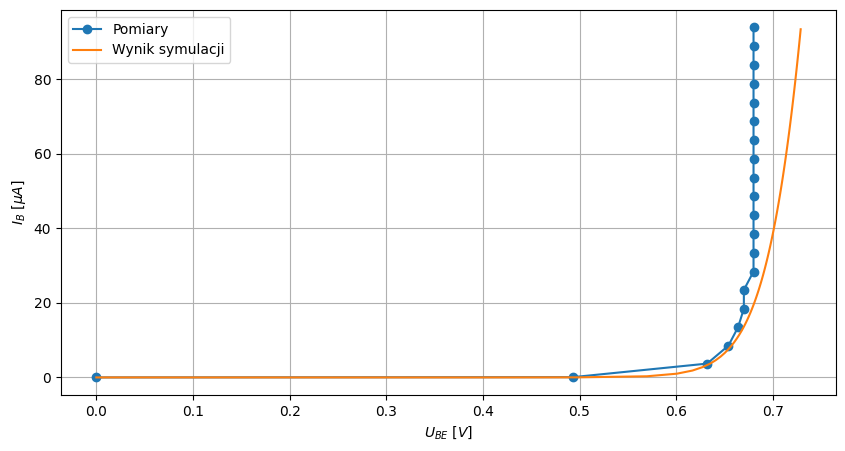

In [94]:
v_be = raw.get_trace("V(b)").get_wave()
i_b = raw.get_trace("Ib(Q1)").get_wave()*1e6

data = pd.read_excel(BASE_DIR + "..\\csv\\IB_UBE.xls")
freq_zmierzone = (data["U1 [V]"].values - data["UB [V]"].values)
G_zmierzone = (data["UB [V]"].values)/99281 * 1e6
# === RYSUJEMY WYKRES ===

fig,ax = plt.subplots(figsize=(10, 5))
ax.plot(freq_zmierzone, G_zmierzone, label="Pomiary", linestyle="-", marker="o")
ax.plot(v_be, i_b, label=f"Wynik symulacji")


ax.set_xlabel("$U_{BE} \  [V]$")
ax.set_ylabel("$I_B \ [\mu A]$")
# ax.set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax.grid(True)
ax.legend()

fig.savefig("ib_ube.png")


### $I_C = f(U_{CE})$

In [69]:
# === KONFIGURACJA ===
asc_file = BASE_DIR + "npn_char.asc"
# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
sim.add_instructions(".step param VB list 3 6 9")
sim.add_instructions(".dc V1 0 10 0.1")
sim.add_instructions(".MODEL BC547A NPN(IS=1.533E-14 ISE=7.932E-16 ISC=8.305E-14 XTI=3 BF=178.7 BR=8.628 IKF=0.1216 IKR=0.1121 XTB=1.5 VAF=69.7 VAR=44.7 VJE=0.4209 VJC=0.2 RE=0.6395 RC=0.6508 RB=1 RBM=1 IRB=1E-06 CJE=1.61E-11 CJC=4.388p XCJC=0.6193 FC=0.7762 NF=1.002 NR=1.004 NE=1.436 NC=1.207 MJE=0.3071 MJC=0.2793 TF=4.995E-10 TR=1m2 ITF=0.7021 VTF=3.523 XTF=139 EG=1.11 VCEO=50 ICRATING=100m MFG=PHILIPS)")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

ASC File Path: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Tranzystory\tranzystory\npn_char.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...


<RunTask(RunTask#1, started 14168)>

In [70]:
# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")
# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim

Sprawdzam plik .raw: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Tranzystory\tranzystory\npn_char_1.raw
Dostępne sygnały: ['V1', 'V(b)', 'V(n001)', 'V(c)', 'V(n002)', 'Ic(Q1)', 'Ib(Q1)', 'Ie(Q1)', 'Is(Q1)', 'I(R2)', 'I(V2)', 'I(V1)', 'I(R1)']


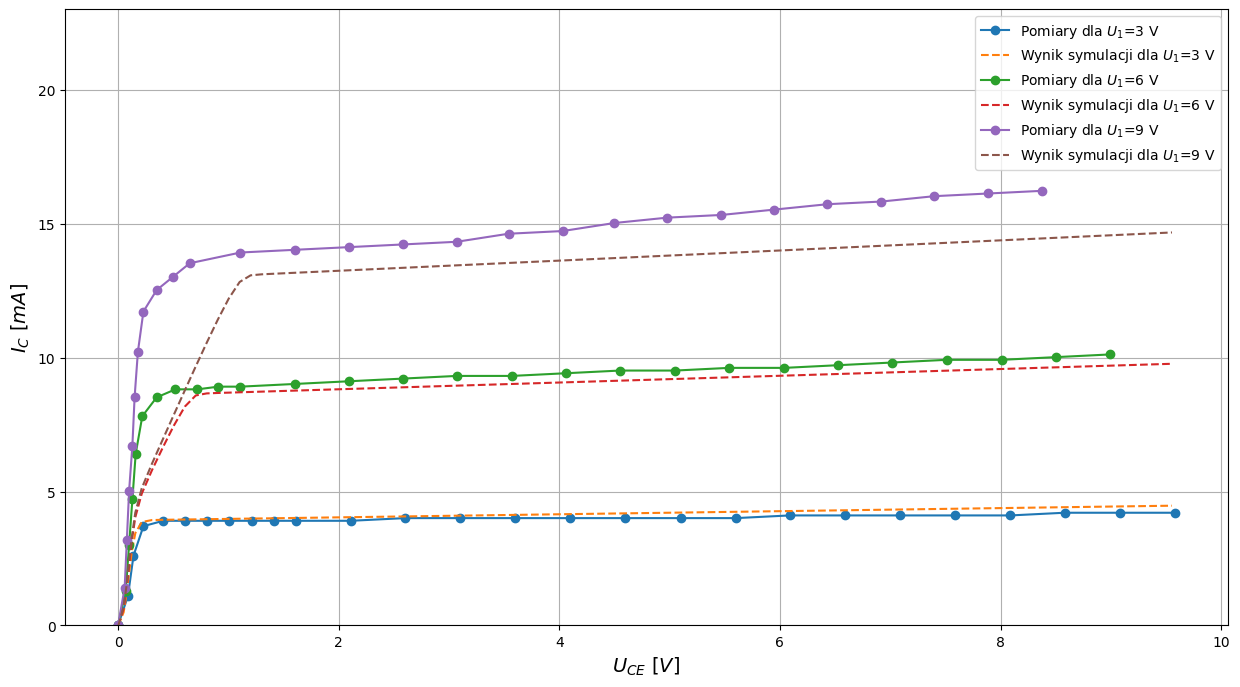

In [88]:
v_ce = raw.get_trace("V(c)").get_wave()
i_c = {}
v_ce_pom = {}
i_c_pom = {}

for step in raw.get_steps():
    i_c[step] = raw.get_trace("Ic(Q1)").get_wave(step)*1e3
    data = pd.read_excel(BASE_DIR + f"..\\csv\\IC_UCE_{3+3*step}V.xls")
    i_c_pom[step] = ( data["Uc [V]"].values)/99.83 * 1e3
    v_ce_pom[step] = (data["U2 [V]"].values -data["Uc [V]"].values)
# data = pd.read_csv(BASE_DIR + "csv\\wtornik.csv")
# freq_zmierzone = data["frequency"].values
# G_zmierzone = data["G"].values
# === RYSUJEMY WYKRES ===

fig,ax = plt.subplots(figsize=(15, 8))
# ax.plot(freq_zmierzone, G_zmierzone, label=f"Pomiary", linestyle="-", marker="o")
for step, i_c in i_c.items():
    ax.plot(v_ce_pom[step], i_c_pom[step], label=f"Pomiary dla $U_1$={3 + 3*step} V", marker="o")
    ax.plot(v_ce, i_c, label=f"Wynik symulacji dla $U_1$={3 + 3*step} V", linestyle="--")

ax.set_xlabel("$U_{CE} \  [V]$", fontdict={'size': 14})
ax.set_ylabel("$I_C \ [mA]$", fontdict={'size': 14})
# ax.set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax.grid(True)
ax.legend(loc='upper right', bbox_to_anchor=(1, 1))
ax.set_ylim(0,23)

fig.savefig("ic_uce.png")

## JFET

In [106]:
# === KONFIGURACJA ===
asc_file = BASE_DIR + "jfet_char.asc"
# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim_jfet = SimCommander(asc_file)
sim_jfet.add_instructions(".dc V2 -5 0 0.1")
sim_jfet.add_instructions(".MODEL BF256B NJF(VTO=-3 BETA=1.09m BETATCE=-0.5 LAMBDA=2.31754E-2 RD=7.77648 RS=7.77648 CGS=2.00000p CGD=2.20000p PB=9.91494E-1 IS=2.59121E-16 XTI=3 AF=1 FC=0.5 N=1 NR=2 MFG=PHILIPS)")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim_jfet.run()

ASC File Path: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Tranzystory\tranzystory\jfet_char.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...


<RunTask(RunTask#1, started 13620)>

In [107]:
# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")
# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim_jfet

Sprawdzam plik .raw: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Tranzystory\tranzystory\jfet_char_1.raw
Dostępne sygnały: ['V2', 'V(n002)', 'V(n001)', 'V(g)', 'V(d)', 'I(V1)', 'I(R1)', 'Id(J1)', 'Ig(J1)', 'Is(J1)', 'I(R2)', 'I(V2)']


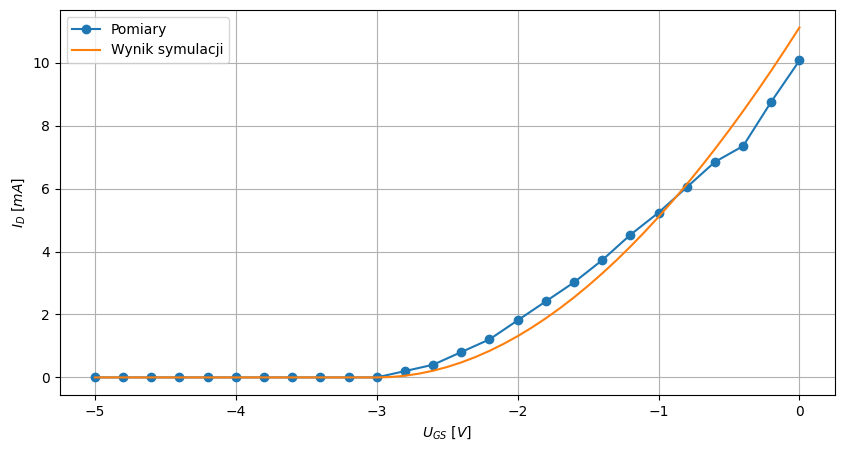

In [109]:
v_ce = raw.get_trace("V(g)").get_wave()

i_d = raw.get_trace("Id(J1)").get_wave()*1e3


data = pd.read_excel(BASE_DIR + "..\\csv\\ID_UGS.xls")
u_gs = -(data["UGS [V]"].values)
i_d_zmierzone = (data["UD [V]"].values)/99.283 * 1e3
# === RYSUJEMY WYKRES ===

fig,ax = plt.subplots(figsize=(10, 5))
ax.plot(u_gs, i_d_zmierzone, label=f"Pomiary", linestyle="-", marker="o")

ax.plot(v_ce, i_d, label="Wynik symulacji")


ax.set_xlabel("$U_{GS} \  [V]$")
ax.set_ylabel("$I_D \ [mA]$")
# ax.set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax.grid(True)
ax.legend()

fig.savefig("jfet.png")

## Obciazenia

In [116]:
# === KONFIGURACJA ===
asc_file = BASE_DIR + "npn_char.asc"
# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
sim.add_instructions(".step param RB list 47k 26.7k 10.01k")
sim.add_instructions(".dc V1 0 100 0.1")
sim.add_instructions(".MODEL BC547A NPN(IS=1.533E-14 ISE=7.932E-16 ISC=8.305E-14 XTI=3 BF=178.7 BR=8.628 IKF=0.1216 IKR=0.1121 XTB=1.5 VAF=69.7 VAR=44.7 VJE=0.4209 VJC=0.2 RE=0.6395 RC=0.6508 RB=1 RBM=1 IRB=1E-06 CJE=1.61E-11 CJC=4.388p XCJC=0.6193 FC=0.7762 NF=1.002 NR=1.004 NE=1.436 NC=1.207 MJE=0.3071 MJC=0.2793 TF=4.995E-10 TR=1m2 ITF=0.7021 VTF=3.523 XTF=139 EG=1.11 VCEO=50 ICRATING=100m MFG=PHILIPS)")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

ASC File Path: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Tranzystory\tranzystory\npn_char.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...


<RunTask(RunTask#1, started 9068)>

In [117]:
# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")
# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim

Sprawdzam plik .raw: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Tranzystory\tranzystory\npn_char_1.raw
Dostępne sygnały: ['V1', 'V(b)', 'V(n002)', 'V(n001)', 'V(c)', 'V(n003)', 'Ic(Q1)', 'Ib(Q1)', 'Ie(Q1)', 'Is(Q1)', 'I(R2)', 'I(V2)', 'I(D1)', 'I(V1)', 'I(R1)']


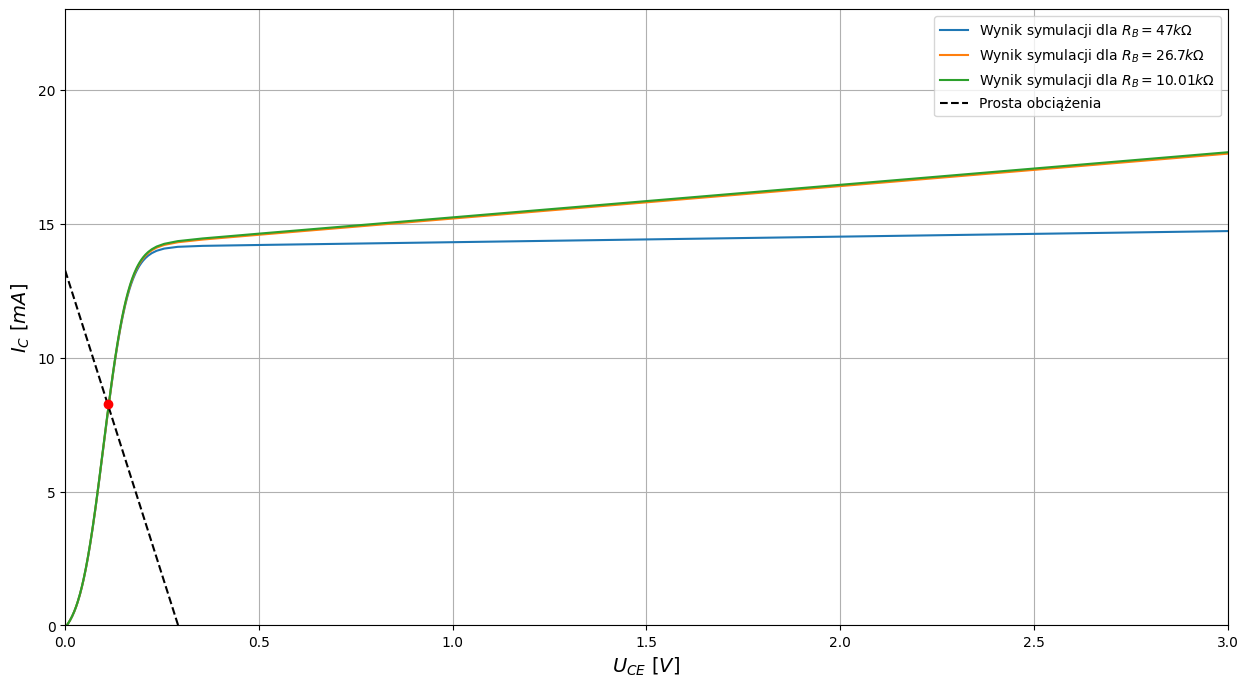

In [137]:
v_ce = raw.get_trace("V(c)").get_wave()
i_c = {}
rb = ["47 k", "26.7 k", "10.01 k"]
for step in raw.get_steps():
    i_c[step] = raw.get_trace("Ic(Q1)").get_wave(step)*1e3

fig,ax = plt.subplots(figsize=(15, 8))

for step, i_c in i_c.items():
    ax.plot(v_ce, i_c, label=f"Wynik symulacji dla $R_B={rb[step]}\Omega$ ")

x = np.linspace(0, 0.5, 100)
ax.plot(x, -x/0.022 + 13.25, label="Prosta obciążenia", linestyle="--", color='black')
ax.plot(0.11, 8.25, "ro")

ax.set_xlabel("$U_{CE} \  [V]$", fontdict={'size': 14})
ax.set_ylabel("$I_C \ [mA]$", fontdict={'size': 14})
# ax.set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax.grid(True)
ax.legend(loc='upper right', bbox_to_anchor=(1, 1))
ax.set_ylim(0,23)
ax.set_xlim(0,3)

fig.savefig("obiz.png")